In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
# !unzip -q "/content/drive/MyDrive/Datasets/chest_xray.zip" -d "/content/"

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

In [28]:
import warnings             # Used to control warning messages
warnings.filterwarnings('ignore') # To ignore unnecessary warning messages for clean

In [29]:
# generators
train_ds = keras.utils.image_dataset_from_directory(
    directory = '/kaggle/input/datasets/donnaahmed/chest-x-ray/chest_xray/train',
    labels = 'inferred',
    label_mode = 'int',
    color_mode = 'grayscale',
    batch_size = 32,
    image_size = (256,256)
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory = '/kaggle/input/datasets/donnaahmed/chest-x-ray/chest_xray/val',
    labels = 'inferred',
    label_mode = 'int',
    color_mode = 'grayscale',
    batch_size = 32,
    image_size  =(256,256)
)

test_ds = keras.utils.image_dataset_from_directory(
    directory = '/kaggle/input/datasets/donnaahmed/chest-x-ray/chest_xray/test',
    labels = 'inferred',
    label_mode = 'int',
    color_mode = 'grayscale',
    batch_size = 32,
    image_size  =(256,256)
)

Found 5226 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.


In [30]:
# Normalize
def preprocess(image, label):
  image = tf.cast(image/255, tf.float32)
  return image, label

In [31]:
train_ds_ = train_ds.map(preprocess)
validation_ds_ = validation_ds.map(preprocess)
test_ds_ = test_ds.map(preprocess)

In [45]:
model = Sequential([
    layers.Input(shape=(256, 256, 1)),
    # Data Augmentation
    layers.RandomContrast(0.02),
    layers.RandomBrightness(0.005),
    #CNN

    # Feature Extraction (Low-level edges)
    layers.Conv2D(64, kernel_size=(3,3), padding='same', activation='relu'),
    layers.MaxPool2D((2,2)),


    # Intermediate Features (Textures & Shapes)
    layers.Conv2D(128, kernel_size=(3,3), padding='same', activation='relu'),
    layers.MaxPool2D((2,2)),


    # High-level Complex Patterns
    layers.Conv2D(256, kernel_size=(3,3), padding='same', activation='relu'),
    layers.MaxPool2D((2,2)),


    # Dense Network
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    # Output Layer
    layers.Dense(1, activation='sigmoid')

])

In [46]:
model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy',
               keras.metrics.Precision(name='precision'),
               keras.metrics.Recall(name='recall'),
               keras.metrics.AUC(name='auc')]

)

* **Accuracy:** Percentage of total correct predictions (can be misleading if the dataset is imbalanced).
* **Precision:** Out of all predicted positive cases, how many were actually sick (low precision = too many false alarms).
* **Recall (Sensitivity):** Out of all actual sick cases, how many were successfully caught (low recall = dangerous missed diagnoses).
* **AUC:** Measures the model's overall ability to separate and distinguish between classes over different thresholds.

In [47]:
from tensorflow.keras.callbacks import EarlyStopping

# Define the Early Stopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',         # Watch the validation loss
    patience=5,                 # Increased to 5 to give data augmentation room to settle
    restore_best_weights=True,  # Roll back to the best epoch's weights automatically
    verbose=1                   # Prints a message when early stopping is triggered
)

In [48]:
history = model.fit(train_ds_, validation_data=validation_ds_, epochs=30, callbacks=[early_stopping])

Epoch 1/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 33s 173ms/step - accuracy: 0.7717 - auc: 0.7812 - loss: 0.5456 - precision: 0.7890 - recall: 0.9459 - val_accuracy: 0.8125 - val_auc: 0.9531 - val_loss: 0.4499 - val_precision: 0.7273 - val_recall: 1.0000
Epoch 2/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 24s 145ms/step - accuracy: 0.8433 - auc: 0.8927 - loss: 0.3541 - precision: 0.8774 - recall: 0.9174 - val_accuracy: 0.8125 - val_auc: 0.9219 - val_loss: 0.4242 - val_precision: 0.7778 - val_recall: 0.8750
Epoch 3/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 23s 142ms/step - accuracy: 0.8718 - auc: 0.9284 - loss: 0.2922 - precision: 0.9022 - recall: 0.9282 - val_accuracy: 0.8125 - val_auc: 0.8984 - val_loss: 1.4726 - val_precision: 0.7273 - val_recall: 1.0000
Epoch 4/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 24s 145ms/step - accuracy: 0.8798 - auc: 0.9345 - loss: 0.2802 - precision: 0.9030 - recall: 0.9393 - val_accuracy: 0.8125 - val_auc: 0.9531 - val_loss: 0.4106 - val_precision: 0.7778 - val_recall: 0.8750
Epoch 5/30
164/164 ━

In [49]:
model.evaluate(test_ds_)

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.7212 - auc: 0.7496 - loss: 5.3719 - precision: 0.7000 - recall: 0.9692


[5.371862888336182,
 0.7211538553237915,
 0.699999988079071,
 0.9692307710647583,
 0.7495836019515991]

In [50]:
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_contrast_3               │ (None, 256, 256, 1)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness_3             │ (None, 256, 256, 1)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 256, 256, 64)   │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 128, 128, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 64, 64, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 262144)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │    16,777,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,441,029 (196.23 MB)

 Trainable params: 17,147,009 (65.41 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 34,294,020 (130.82 MB)

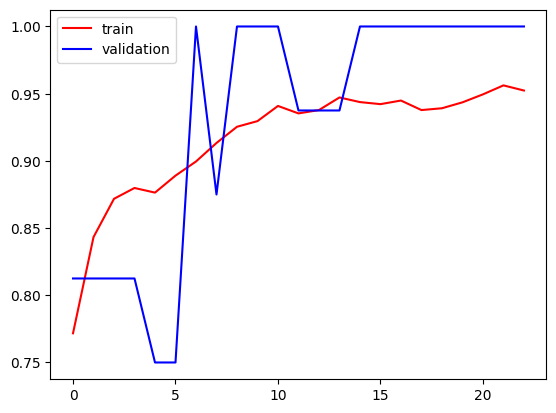

In [51]:
plt.plot(history.history['accuracy'], color='red', label='train')
plt.plot(history.history['val_accuracy'], color='blue', label='validation')
plt.legend()
plt.show()

### Training vs. Validation Accuracy Observations

* **Training Progress (Red Line):** Shows a smooth, steady, and consistent upward trajectory from ~77% to ~95%, indicating stable learning over epochs.
* **Validation Volatility (Blue Line):** Exhibits early fluctuations (ranging between 75% and 81% during the first 5 epochs) as the model searches for optimal weights.
* **Stabilization & Generalization:** After epoch 7, validation accuracy stabilizes at high levels (frequently reaching 100%), while the training curve maintains a healthy, controlled climb without negative divergence, confirming strong regularization.
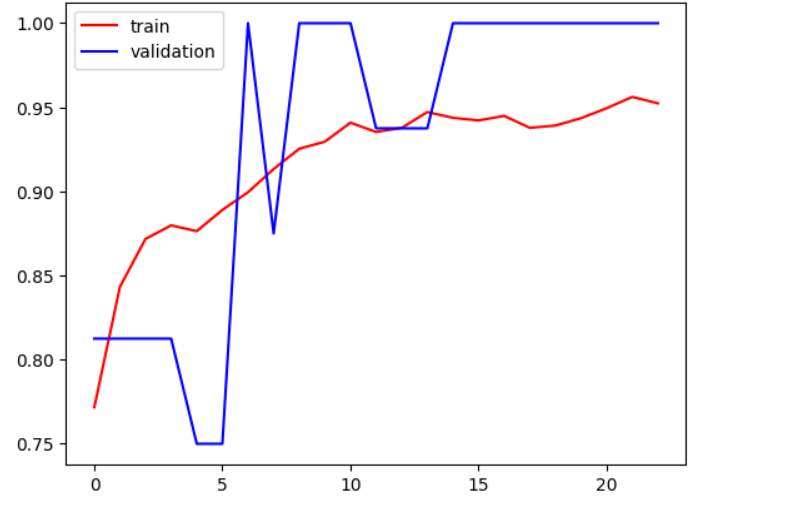

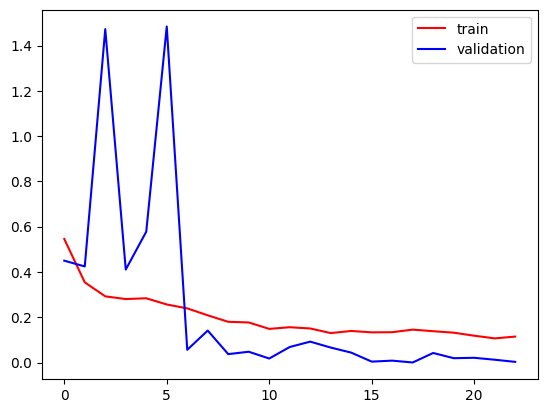

In [52]:
plt.plot(history.history['loss'], color='red', label='train')
plt.plot(history.history['val_loss'], color='blue', label='validation')
plt.legend()
plt.show()

### Training vs. Validation Loss Observations

* **Training Loss (Red Line):** Decreases smoothly and consistently from ~0.55 down below 0.15, showing a steady optimization and convergence of the model's weights.
* **Validation Loss Volatility (Blue Line):** Experiences sharp spikes reaching over 1.4 during the first 6 epochs, reflecting high initial uncertainty and sensitivity on validation batches.
* **Post-Convergence Stability:** After epoch 6, validation loss drops sharply and remains consistently low (close to 0) for the remainder of training, indicating excellent generalization and effective error minimization.

### **Transfer Learning**

In [90]:
def preprocess_pre(image, label):
    #  Convert 1-channel grayscale to 3-channel RGB (duplicates the channel)
    image = tf.image.grayscale_to_rgb(image)
    

    image = tf.cast(image/255, tf.float32)
    
    return image, label

In [91]:
train_dataset = train_ds.map(preprocess_pre)
validation_dataset = validation_ds.map(preprocess_pre)
test_dataset = test_ds.map(preprocess_pre)


In [92]:
# Load DenseNet121 directly (Without extra Sequential wrapper)
base_model = keras.applications.DenseNet121(
    input_shape=(256, 256, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze the base model layers
base_model.trainable = False

In [93]:
model_transfer = Sequential([
    layers.Input(shape=(256, 256, 3)),
    # Data Augmentation
    layers.RandomContrast(0.02),
    layers.RandomBrightness(0.005),

    # Transfer Learning
    base_model,

    # Custom Classification Head
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

In [94]:
model_transfer.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy',
               keras.metrics.Precision(name='precision'),
               keras.metrics.Recall(name='recall'),
               keras.metrics.AUC(name='auc')]

)

In [98]:
history_transfer = model_transfer.fit(train_dataset, validation_data=validation_dataset, epochs=30, callbacks = [early_stopping])

Epoch 1/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 17s 104ms/step - accuracy: 0.9508 - auc: 0.9806 - loss: 0.1366 - precision: 0.9446 - recall: 0.9920 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0040 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 2/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - accuracy: 0.9516 - auc: 0.9828 - loss: 0.1364 - precision: 0.9473 - recall: 0.9900 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0048 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 3/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 17s 103ms/step - accuracy: 0.9466 - auc: 0.9819 - loss: 0.1396 - precision: 0.9423 - recall: 0.9887 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 5.5509e-04 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 4/30
164/164 ━━━━━━━━━━━━━━━━━━━━ 16s 100ms/step - accuracy: 0.9447 - auc: 0.9813 - loss: 0.1366 - precision: 0.9420 - recall: 0.9864 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0070 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 5/30
164/1

In [99]:
model_transfer.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_contrast_8               │ (None, 256, 256, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness_8             │ (None, 256, 256, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 8, 8, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │     8,388,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,228,677 (122.94 MB)

 Trainable params: 8,397,057 (32.03 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

 Optimizer params: 16,794,116 (64.06 MB)

In [101]:
model_transfer.evaluate(test_dataset)

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - accuracy: 0.8109 - auc: 0.8354 - loss: 2.4684 - precision: 0.7677 - recall: 1.0000


[2.4683618545532227,
 0.8108974099159241,
 0.7677165269851685,
 1.0,
 0.8353988528251648]

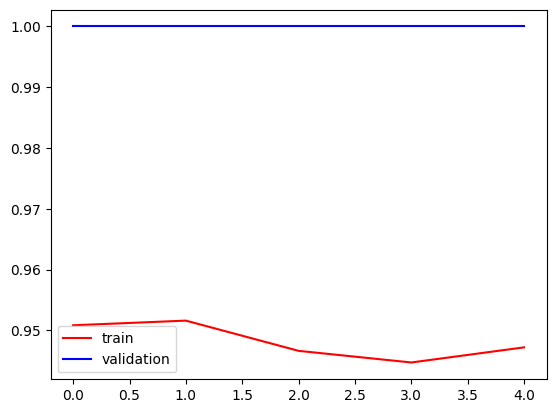

In [102]:
plt.plot(history_transfer.history['accuracy'], color='red', label='train')
plt.plot(history_transfer.history['val_accuracy'], color='blue', label='validation')
plt.legend()
plt.show()

### Pre-Trained DenseNet121 Accuracy Observations

* **Immediate Validation Perfection (Blue Line):** The validation accuracy instantly hits 1.0 (100%) right from epoch 0 and remains completely flat and stable throughout all 5 epochs.
* **Consistent Training Accuracy (Red Line):** The training accuracy hovers tightly between ~94.5% and ~95.2%, showing a stable and high level of performance from the very beginning.
* **Inverted Gap Phenomenon:** Unlike typical training curves, the training accuracy sits slightly *below* the validation accuracy (~95% vs 100%), which is heavily influenced by transfer learning weights and data preprocessing.

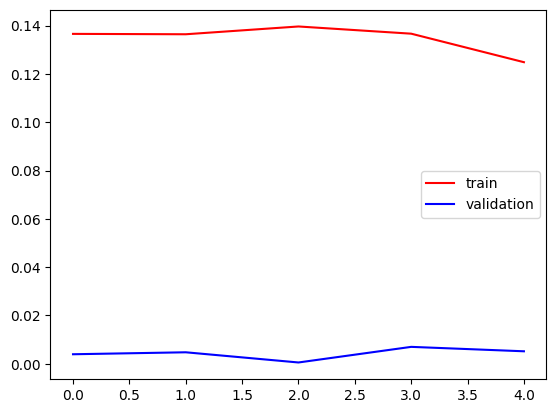

In [103]:
plt.plot(history_transfer.history['loss'], color='red', label='train')
plt.plot(history_transfer.history['val_loss'], color='blue', label='validation')
plt.legend()
plt.show()

### Pre-Trained DenseNet121 Loss Observations

* **Extremely Low Validation Loss (Blue Line):** The validation loss stays flat and exceptionally close to 0 throughout all epochs, perfectly matching the 100% validation accuracy seen previously.
* **Stable Training Loss (Red Line):** The training loss remains steady and low, hovering between ~0.12 and ~0.14, showing that the model is maintaining a consistent error rate without wild fluctuations.
* **Consistent Convergence Gap:** A small, stable gap exists between the training loss (~0.13) and validation loss (~0.005), which highlights the powerful benefit of leveraging pre-trained ImageNet feature extractors.

### Why Grayscale (1-Channel) for Custom Models vs. RGB (3-Channels) for Pre-Trained Models

* **Nature of Chest X-Ray Data (Custom Models):** 
  * Medical X-rays are inherently single-channel (grayscale) images capturing density variations. 
  * Training a custom CNN from scratch allows you to process this raw data directly in 1 channel, keeping memory usage lower and avoiding redundant channel replication.

* **ImageNet Architecture Constraints (Pre-Trained Models):** 
  * Models like **DenseNet121** with `weights='imagenet'` are built and pre-trained on ImageNet, a massive database of natural, 3-channel (RGB) color photographs.
  * Their first convolutional layer is hardcoded with spatial weight filters expecting a depth of 3 channels. 

* **The Bridge (Duplication & Preprocessing):** 
  * To leverage the powerful, pre-learned feature extractors of a transfer learning model, single-channel X-rays must be duplicated across three identical channels (`tf.image.grayscale_to_rgb`) or passed through specific preprocessing pipelines. 
  * This satisfies the network's strict shape requirements while preserving the underlying clinical grayscale information.

### **Making Predictions and Categorizing Output**

In [105]:
import cv2

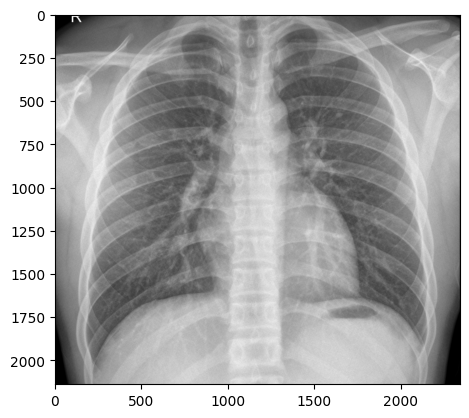

In [112]:
test_img = cv2.imread('/kaggle/input/datasets/donnaahmed/chest-x-ray/chest_xray/test/NORMAL/IM-0029-0001.jpeg')
plt.imshow(test_img)
test_img = cv2.resize(test_img, (256,256))
test_img = test_img/255
test_input = test_img.reshape((1,256,256,3))

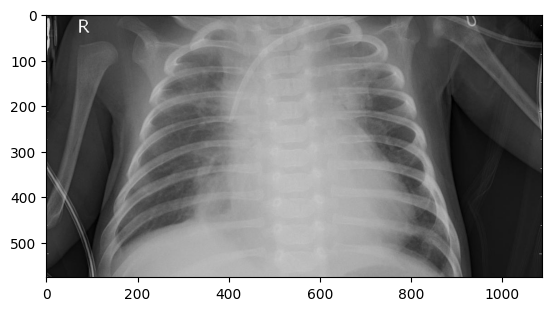

In [114]:
test_img2 = cv2.imread('//kaggle/input/datasets/donnaahmed/chest-x-ray/chest_xray/test/PNEUMONIA/person109_bacteria_526.jpeg')
plt.imshow(test_img2)
test_img2 = cv2.resize(test_img2, (256,256))
test_img2 = test_img2/255
test_input2 = test_img2.reshape((1,256,256,3))

In [108]:
def predict(x):
  pred  = model_transfer.predict(x)
  print(pred)
  if pred[0][0] < 0.5:
    print("NORMAL")
  else:
    print("PNEUMONIA")

In [113]:
predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
[[0.02691802]]
NORMAL


In [115]:
predict(test_input2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
[[1.]]
PNEUMONIA
